# 07. Embedding Extraction — số liệu, Ablation và Nested CV

**258 participant, group, Stratified 6-Fold, seed 42.** GAF/ViT-B16 và CWT/EfficientNet-B4.
Notebook chỉ đọc artifact đã chạy, không fit mô hình hoặc chọn cấu hình mới.
Bảng số giữ metric ở **0–1**, biểu đồ dùng %. `mean_*` là trung bình 6 fold,
các cột metric không có tiền tố là pooled OOF. SD giữa fold không phải CI.
Kết quả grid là thăm dò; ưu tiên nested CV để đánh giá quy trình lựa chọn.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

ROOT=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
OUT=ROOT/'results/embedding_ablation'
validation=json.loads((OUT/'validation.json').read_text())
assert validation.get('numerical_validation_passed'), 'Chạy report/validation số liệu trước.'
summary=pd.read_csv(OUT/'summary.csv')
nested=pd.read_csv(OUT/'nested_summary.csv')
delta=pd.read_csv(OUT/'nested_comparison.csv')
matched=pd.read_csv(OUT/'ablation_matched.csv')
selected=pd.read_csv(OUT/'selected_by_fold.csv')
oof=pd.read_csv(OUT/'nested_oof.csv')
costs=pd.read_csv(OUT/'extraction_costs.csv')
BRANCHES=['GAF','CWT']
MODES=['original','group_adapter','channel_mean','channel_concat']
METRICS=[('accuracy','Accuracy'),('f1_macro','F1 macro'),('auc','ROC-AUC')]
pd.set_option('display.max_columns',None)
pd.set_option('display.max_colwidth',None)
pd.set_option('display.float_format','{:.6f}'.format)
FIG=OUT/'figures'; FIG.mkdir(exist_ok=True)
manifest=[]
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none'})
def show(fig,name,description,sources,n_participants=258):
    for ext in ('png','svg'): fig.savefig(FIG/(name+'.'+ext),dpi=180,facecolor='white')
    manifest.append(dict(name=name,description=description,sources=sources,n_participants=n_participants,
        source_sha256={p:hashlib.sha256((OUT/p).read_bytes()).hexdigest() for p in sources}))
    plt.show(); plt.close(fig)
print('192 cấu hình; metric được kiểm tra lại từ OOF. Không thực hiện Fusion.')

192 cấu hình; metric được kiểm tra lại từ OOF. Không thực hiện Fusion.


## Kết quả cuối cùng — bảng số Nested CV

`original_raw`: inner CV chọn classifier trên embedding gốc;
`original_compact`: giữ nguyên quy trình 54 ứng viên giảm chiều cũ;
các mode mới có đối chứng raw và compact riêng. `new_selected` chọn giữa 72 ứng viên mới;
`all_selected` cho phép cả 54 ứng viên cũ thắng. Không xếp hạng outer test để chọn cấu hình.

In [2]:
columns=['branch','scenario','mean_features','accuracy','f1_macro','f1_weighted','f1_binary','auc',
         'balanced_accuracy','mean_accuracy','mean_f1_macro','mean_auc','std_accuracy','std_f1_macro','std_auc']
nested[columns].sort_values(['branch','scenario']).reset_index(drop=True)

,branch,scenario,mean_features,accuracy,f1_macro,f1_weighted,f1_binary,auc,balanced_accuracy,mean_accuracy,mean_f1_macro,mean_auc,std_accuracy,std_f1_macro,std_auc
0,CWT,all_selected,208.000000,0.643411,0.632729,0.639526,0.695364,0.670295,0.632350,0.643411,0.630476,0.674530,0.074515,0.074704,0.038419
1,CWT,channel_concat_compact,208.000000,0.658915,0.652886,0.657851,0.698630,0.714077,0.652296,0.658915,0.649781,0.717525,0.061821,0.059362,0.050202
2,CWT,channel_concat_raw,175616.000000,0.662791,0.660952,0.663662,0.685921,0.737185,0.662603,0.662791,0.659049,0.739076,0.065365,0.065221,0.087655
3,CWT,channel_mean_compact,8486.666667,0.612403,0.606347,0.611646,0.655172,0.676984,0.606081,0.612403,0.603782,0.660310,0.107749,0.109620,0.097783
4,CWT,channel_mean_raw,25088.000000,0.662791,0.657851,0.662313,0.698962,0.726786,0.657495,0.662791,0.655052,0.728175,0.060196,0.067238,0.066508
5,CWT,group_adapter_compact,12663.166667,0.666667,0.663757,0.667152,0.695035,0.698085,0.664396,0.666667,0.663752,0.691778,0.078750,0.078743,0.093005
6,CWT,group_adapter_raw,25088.000000,0.662791,0.660089,0.663378,0.690391,0.706050,0.660900,0.662791,0.659812,0.704856,0.061967,0.061656,0.081943
7,CWT,new_selected,208.000000,0.658915,0.652886,0.657851,0.698630,0.714077,0.652296,0.658915,0.649781,0.717525,0.061821,0.059362,0.050202
8,CWT,original_compact,216.666667,0.658915,0.653586,0.658249,0.696552,0.702159,0.653147,0.658915,0.647895,0.704500,0.068463,0.071140,0.056932
9,CWT,original_raw,25088.000000,0.686047,0.683953,0.686744,0.709677,0.755488,0.685284,0.686047,0.681032,0.758514,0.061967,0.064865,0.063031


## Chênh lệch với baseline và nghiên cứu giảm chiều cũ

Mọi cột delta là **điểm phần trăm**. Đây là chênh lệch giữa các quy trình được chọn
bên trong train, đánh giá trên cùng outer test participant.

In [3]:
delta.sort_values(['branch','scenario']).reset_index(drop=True)

,branch,scenario,mean_features,delta_vs_original_raw_accuracy_pp,delta_vs_original_raw_f1_macro_pp,delta_vs_original_raw_auc_pp,delta_vs_original_compact_accuracy_pp,delta_vs_original_compact_f1_macro_pp,delta_vs_original_compact_auc_pp
0,CWT,all_selected,208.000000,-4.263566,-5.055657,-8.398487,-1.550388,-1.741918,-2.997076
1,CWT,channel_concat_compact,208.000000,-2.713178,-3.125078,-4.098970,0.000000,0.188661,1.302441
2,CWT,channel_concat_raw,175616.000000,-2.325581,-2.198315,-1.943809,0.387597,1.115424,3.457602
3,CWT,channel_mean_compact,8486.666667,-7.364341,-7.725004,-9.820430,-4.651163,-4.411265,-4.419019
4,CWT,channel_mean_raw,25088.000000,-2.325581,-2.598065,-3.033944,0.387597,0.715674,2.367468
5,CWT,group_adapter_compact,12663.166667,-1.937984,-1.727983,-6.673659,0.775194,1.585756,-1.272248
6,CWT,group_adapter_raw,25088.000000,-2.325581,-2.121969,-5.365815,0.387597,1.191770,0.035596
7,CWT,new_selected,208.000000,-2.713178,-3.125078,-4.098970,0.000000,0.188661,1.302441
8,CWT,original_compact,216.666667,-2.713178,-3.313739,-5.401411,0.000000,0.000000,0.000000
9,CWT,original_raw,25088.000000,0.000000,0.000000,0.000000,2.713178,3.313739,5.401411


## Bảng Ablation cấu hình cố định — đủ 192 hàng

Lưới chung gồm 8 reducer × 4 mode × 3 classifier × 2 nhánh. Xếp theo mean F1 macro.
`original` OOF giữ nguyên từ đợt trước; các ứng viên ngoài lưới chung của đợt trước
vẫn được giữ cho quy trình `original_compact`. Không coi bảng thắng này là xác nhận độc lập.

In [4]:
fixed_columns=['branch','mode','reducer','classifier','raw_features','mean_features',
               'accuracy','f1_macro','auc','mean_accuracy','mean_f1_macro','mean_auc',
               'std_accuracy','std_f1_macro','std_auc','mean_classifier_fit_seconds']
with pd.option_context('display.max_rows',None):
    display(summary.sort_values(['mean_f1_macro','mean_accuracy','mean_auc'],ascending=False)[fixed_columns].reset_index(drop=True))

,branch,mode,reducer,classifier,raw_features,mean_features,accuracy,f1_macro,auc,mean_accuracy,mean_f1_macro,mean_auc,std_accuracy,std_f1_macro,std_auc,mean_classifier_fit_seconds
0,GAF,channel_concat,anova_256,LightGBM,75264,256.000000,0.763566,0.756811,0.820310,0.763566,0.756511,0.823748,0.061382,0.060816,0.080161,0.319518
1,GAF,channel_concat,extratrees_256,SVM,75264,256.000000,0.759690,0.753148,0.836303,0.759690,0.751549,0.842719,0.060046,0.064214,0.031580,0.013857
2,GAF,channel_concat,extratrees_256,LightGBM,75264,256.000000,0.744186,0.737222,0.785588,0.744186,0.735818,0.788031,0.032889,0.038677,0.043162,0.321273
3,GAF,channel_concat,none,LightGBM,75264,75264.000000,0.744186,0.735014,0.807358,0.744186,0.733941,0.808708,0.055033,0.053804,0.093848,98.845163
4,GAF,channel_concat,anova_256,LogisticRegression,75264,256.000000,0.736434,0.731201,0.803344,0.736434,0.729490,0.804825,0.031773,0.036280,0.048066,0.015241
5,CWT,channel_concat,anova_256,SVM,175616,256.000000,0.736434,0.727781,0.789328,0.736434,0.726788,0.795835,0.071553,0.073409,0.058146,0.006937
6,GAF,channel_concat,pca_var95,LogisticRegression,75264,189.500000,0.728682,0.727635,0.820736,0.728682,0.725398,0.835406,0.018988,0.020028,0.022509,0.012081
7,GAF,channel_concat,none,LogisticRegression,75264,75264.000000,0.728682,0.728094,0.821283,0.728682,0.725009,0.831366,0.018988,0.019295,0.035547,0.787504
8,GAF,channel_concat,pca_var99,LogisticRegression,75264,209.000000,0.728682,0.727635,0.824324,0.728682,0.724619,0.834675,0.037977,0.042222,0.031747,0.011826
9,CWT,channel_concat,extratrees_256,SVM,175616,256.000000,0.728682,0.721296,0.770690,0.728682,0.720832,0.770871,0.071553,0.072312,0.060528,0.007010


## Tác động riêng của adaptation và giảm chiều — cùng classifier

`delta_adaptation_*_pp`: so với original cùng reducer và classifier.
`delta_reduction_*_pp`: so với cùng mode và classifier, không giảm chiều.
Đây là phép so sánh matched; không gán lợi ích đổi classifier cho adapter.

In [5]:
matched_columns=['branch','mode','reducer','classifier','mean_features']
for m,_ in METRICS:
    matched_columns += ['mean_'+m,'delta_adaptation_'+m+'_pp','delta_reduction_'+m+'_pp']
with pd.option_context('display.max_rows',None): display(matched[matched_columns])

,branch,mode,reducer,classifier,mean_features,mean_accuracy,delta_adaptation_accuracy_pp,delta_reduction_accuracy_pp,mean_f1_macro,delta_adaptation_f1_macro_pp,delta_reduction_f1_macro_pp,mean_auc,delta_adaptation_auc_pp,delta_reduction_auc_pp
0,CWT,channel_concat,anova_256,SVM,256.000000,0.736434,7.751938,8.527132,0.726788,7.887944,11.886659,0.795835,5.883708,4.695366
1,CWT,channel_concat,extratrees_256,SVM,256.000000,0.728682,8.914729,7.751938,0.720832,10.207556,11.291063,0.770871,6.302123,2.199021
2,CWT,channel_concat,anova_256,LogisticRegression,256.000000,0.713178,4.651163,0.387597,0.709585,4.927775,0.175194,0.784710,9.076405,0.250445
3,CWT,channel_concat,none,LogisticRegression,175616.000000,0.709302,2.325581,0.000000,0.707833,2.680108,0.000000,0.782205,2.369057,0.000000
4,CWT,original,pca_var99,LogisticRegression,203.333333,0.713178,0.000000,2.713178,0.707372,0.000000,2.633966,0.760676,0.000000,0.216120
5,CWT,channel_mean,pca_var99,LogisticRegression,203.000000,0.701550,-1.162791,1.162791,0.697164,-1.020785,0.958579,0.732107,-2.856916,-1.567824
6,CWT,channel_concat,extratrees_256,LogisticRegression,256.000000,0.697674,5.813953,-1.162791,0.692410,5.973368,-1.542343,0.745760,6.894864,-3.644483
7,CWT,channel_concat,extratrees_256,LightGBM,256.000000,0.701550,6.201550,0.000000,0.691844,7.017662,0.539856,0.727797,3.194127,-2.682431
8,CWT,channel_concat,pca_var99,LogisticRegression,208.000000,0.693798,-1.937984,-1.550388,0.691557,-1.581475,-1.627616,0.784776,2.410056,0.257119
9,CWT,channel_mean,none,LogisticRegression,25088.000000,0.689922,0.387597,0.000000,0.687578,0.654602,0.000000,0.747785,-1.072972,0.000000


## Bảy kênh ảnh và adapter — một ví dụ input

Cùng participant đầu tiên, tác vụ đầu tiên (RCFT recognition); không chọn ví dụ theo nhãn
hoặc kết quả phân loại. Bảy ảnh xám dùng cùng thang 0–1. `original mean` minh họa
phép gộp sớm tương đương lớp đầu baseline; `group RGB` là adapter cố định mới.
Các màu RGB thể hiện nhóm tín hiệu, không phải ảnh màu tự nhiên.

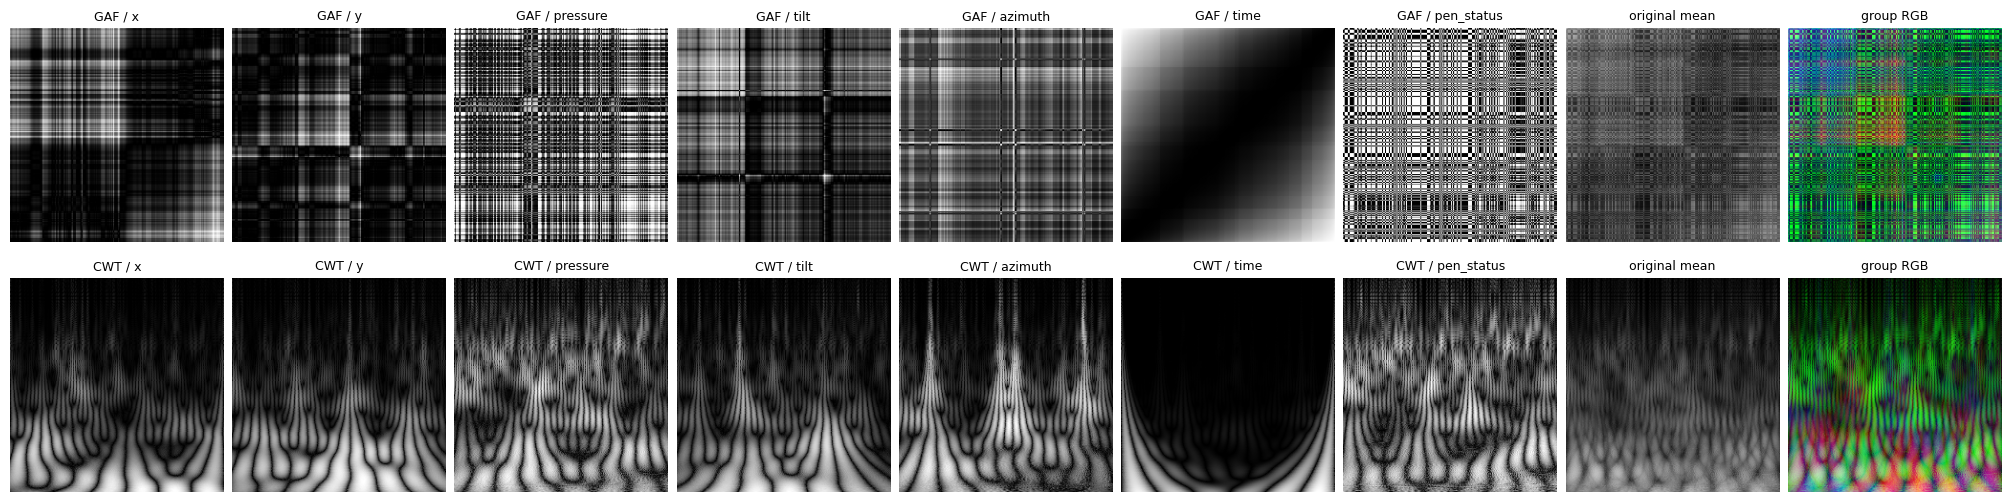

In [6]:
import sys
sys.path.insert(0,str(ROOT/'src'))
from diagramo.features import gaf, cwt, resample, CHANNELS
signal=np.load(ROOT/'data/derived/signals512.npy',mmap_mode='r')[0,0]
gaf_images=(gaf(np.stack([resample(a,224) for a in signal]))+1)/2
cache=ROOT/'data/derived/cwt_cache/00000.npy'
cwt_images=np.load(cache).astype('float32') if cache.exists() else cwt(signal)
adapter_weights=np.array(json.loads((OUT/'embeddings/GAF.json').read_text())['adapter_weights'],dtype='float32')
fig,axes=plt.subplots(2,9,figsize=(20,5),layout='constrained')
for i,(branch,images) in enumerate([('GAF',gaf_images),('CWT',cwt_images)]):
    for j,name in enumerate(CHANNELS):
        axes[i,j].imshow(images[j],cmap='gray',vmin=0,vmax=1)
        axes[i,j].set_title(branch+' / '+name,fontsize=9)
    axes[i,7].imshow(images.mean(0),cmap='gray',vmin=0,vmax=1)
    axes[i,7].set_title('original mean',fontsize=9)
    axes[i,8].imshow(np.einsum('rc,chw->rhw',adapter_weights,images).transpose(1,2,0))
    axes[i,8].set_title('group RGB',fontsize=9)
    for ax in axes[i]: ax.axis('off')
show(fig,'channel_input_examples','First participant/first task: seven grayscale maps, baseline mean and fixed RGB adapter; common grayscale 0–1.',
     ['embeddings/GAF.json','settings.json','../../data/derived/signals512.npy']+
     (['../../data/derived/cwt_cache/00000.npy'] if cache.exists() else []),n_participants=1)

## Nested CV — Accuracy, F1 macro và AUC

Sáu outer fold, mean ± SD; không phải CI. Mọi cách lấy biểu diễn và budget được
chọn bằng inner CV. Cùng thang 0–100% để so sánh trực tiếp các panel.

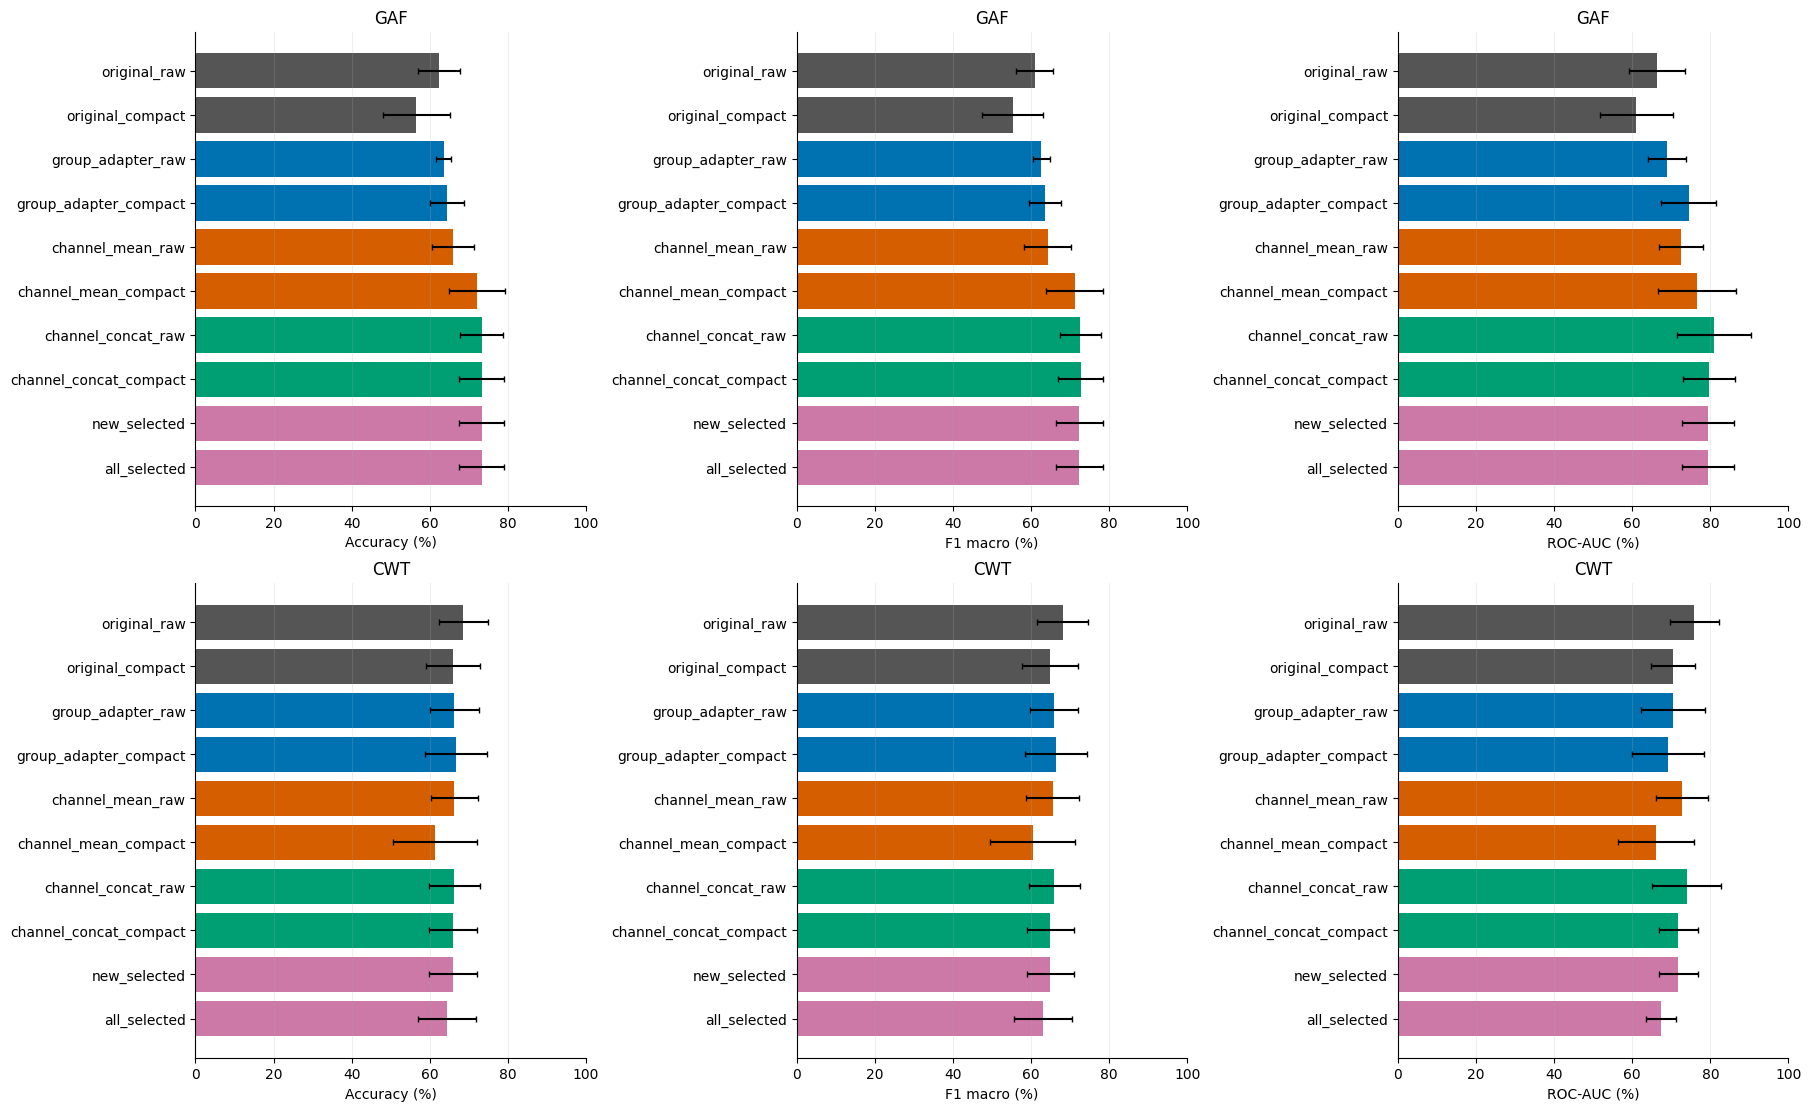

In [7]:
scenarios=['original_raw','original_compact','group_adapter_raw','group_adapter_compact',
           'channel_mean_raw','channel_mean_compact','channel_concat_raw','channel_concat_compact',
           'new_selected','all_selected']
fig,axes=plt.subplots(2,3,figsize=(18,11),layout='constrained')
for i,branch in enumerate(BRANCHES):
    g=nested[nested.branch==branch].set_index('scenario').loc[scenarios]
    for ax,(m,label) in zip(axes[i],METRICS):
        ax.barh(scenarios,100*g['mean_'+m],xerr=100*g['std_'+m],capsize=2,
                color=['#555555']*2+['#0072B2']*2+['#D55E00']*2+['#009E73']*2+['#CC79A7']*2)
        ax.invert_yaxis(); ax.set(xlim=(0,100),xlabel=label+' (%)',title=branch)
        ax.grid(axis='x',alpha=.2)
show(fig,'nested_metrics','Nested procedures: three metrics, mean and SD across six outer folds.', ['nested_summary.csv'])

## Chênh lệch từng outer fold

Mỗi điểm là F1 của quy trình trừ F1 `original_raw` trên cùng 43 participant test.
Vạch đen là mean, không phải CI. Không dùng phép kiểm định độc lập trên các fold.

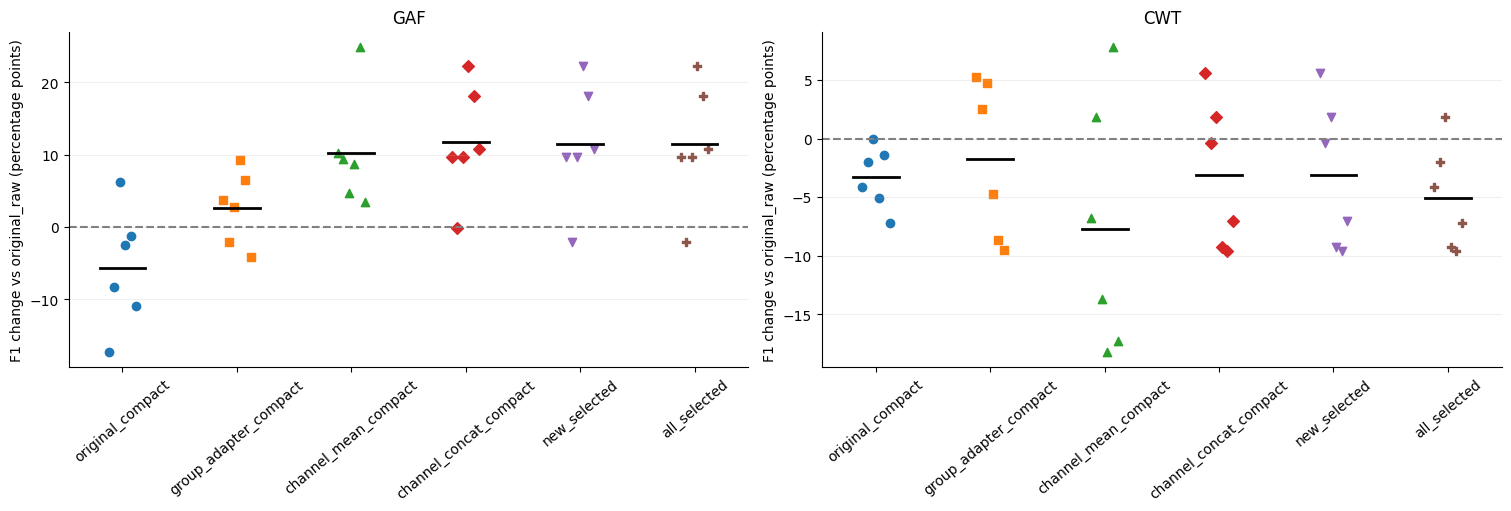

In [8]:
fig,axes=plt.subplots(1,2,figsize=(15,5),layout='constrained')
compare_scenarios=['original_compact','group_adapter_compact','channel_mean_compact',
                   'channel_concat_compact','new_selected','all_selected']
for ax,branch in zip(axes,BRANCHES):
    g=selected[selected.branch==branch].pivot(index='fold',columns='scenario',values='outer_f1_macro')
    for j,scenario in enumerate(compare_scenarios):
        change=100*(g[scenario]-g.original_raw)
        ax.scatter(j+np.linspace(-.12,.12,6),change,marker=['o','s','^','D','v','P'][j])
        ax.plot([j-.2,j+.2],[change.mean()]*2,color='black',lw=2)
    ax.axhline(0,color='gray',ls='--')
    ax.set(title=branch,xticks=range(len(compare_scenarios)),xticklabels=compare_scenarios,
           ylabel='F1 change vs original_raw (percentage points)')
    ax.tick_params(axis='x',labelrotation=40); ax.grid(axis='y',alpha=.2)
show(fig,'paired_outer_folds','Paired outer-fold F1 changes; each point is one fold, black line is mean.', ['selected_by_fold.csv'])

## Adaptation khi giữ nguyên reducer và classifier

Heatmap hiển thị Δ F1 macro điểm phần trăm, tất cả classifier/reducer của ba mode mới,
so với embedding gốc tại cùng ô. Thang màu đối xứng quanh 0 dùng chung giữa các panel.

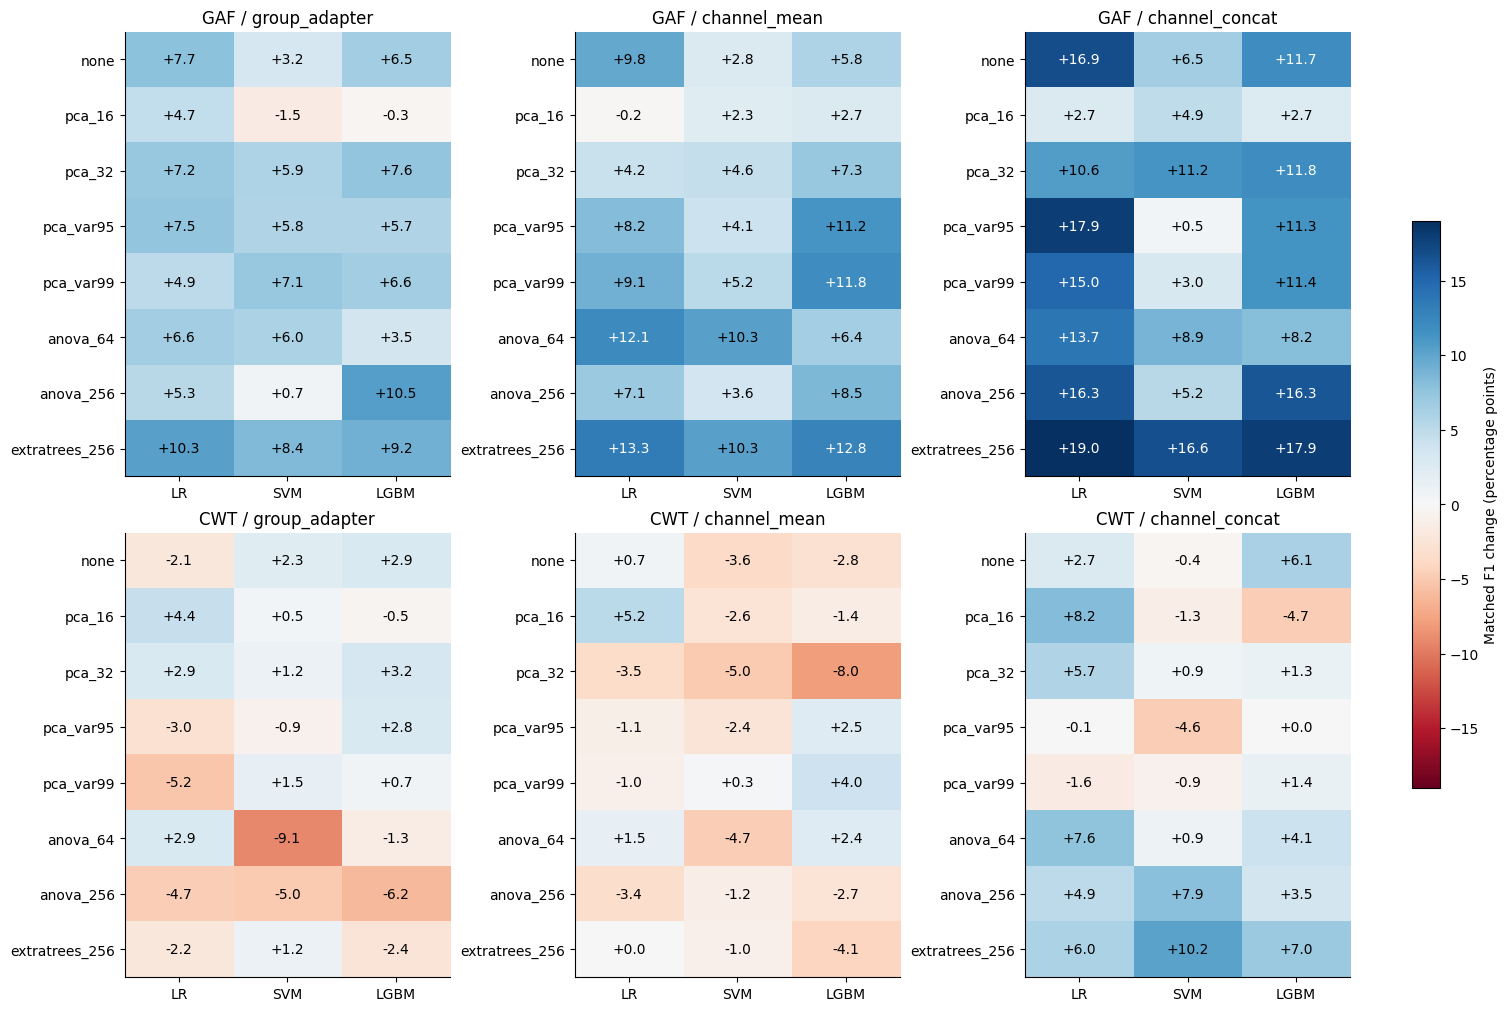

In [9]:
reducer_order=['none','pca_16','pca_32','pca_var95','pca_var99','anova_64','anova_256','extratrees_256']
clf_order=['LogisticRegression','SVM','LightGBM']
limit=max(1,float(matched.delta_adaptation_f1_macro_pp.abs().max()))
fig,axes=plt.subplots(2,3,figsize=(15,10),layout='constrained')
for i,branch in enumerate(BRANCHES):
    for j,mode in enumerate(MODES[1:]):
        ax=axes[i,j]
        g=matched[(matched.branch==branch)&(matched['mode']==mode)].pivot(
            index='reducer',columns='classifier',values='delta_adaptation_f1_macro_pp').reindex(index=reducer_order,columns=clf_order)
        assert not g.isna().any().any()
        im=ax.imshow(g.to_numpy(),cmap='RdBu',vmin=-limit,vmax=limit,aspect='auto')
        for r in range(len(g)):
            for c in range(3):
                v=g.iloc[r,c]; ax.text(c,r,f'{v:+.1f}',ha='center',va='center',
                                      color='white' if abs(v)>limit*.6 else 'black')
        ax.set(title=branch+' / '+mode,xticks=range(3),xticklabels=['LR','SVM','LGBM'],
               yticks=range(len(g)),yticklabels=reducer_order)
fig.colorbar(im,ax=axes,label='Matched F1 change (percentage points)',shrink=.6)
show(fig,'adaptation_matched','Adaptation-only matched F1 deltas for every shared reducer and classifier.', ['ablation_matched.csv'])

## ROC OOF và confusion matrix

ROC dùng pooled OOF AUC, không phải mean AUC các fold. Các quy trình có thể dùng
classifier khác nhau giữa fold, nên độ hiệu chỉnh xác suất giữa fold có thể khác nhau.
Confusion matrix dùng đúng dự đoán đã lưu, không chọn threshold từ test.

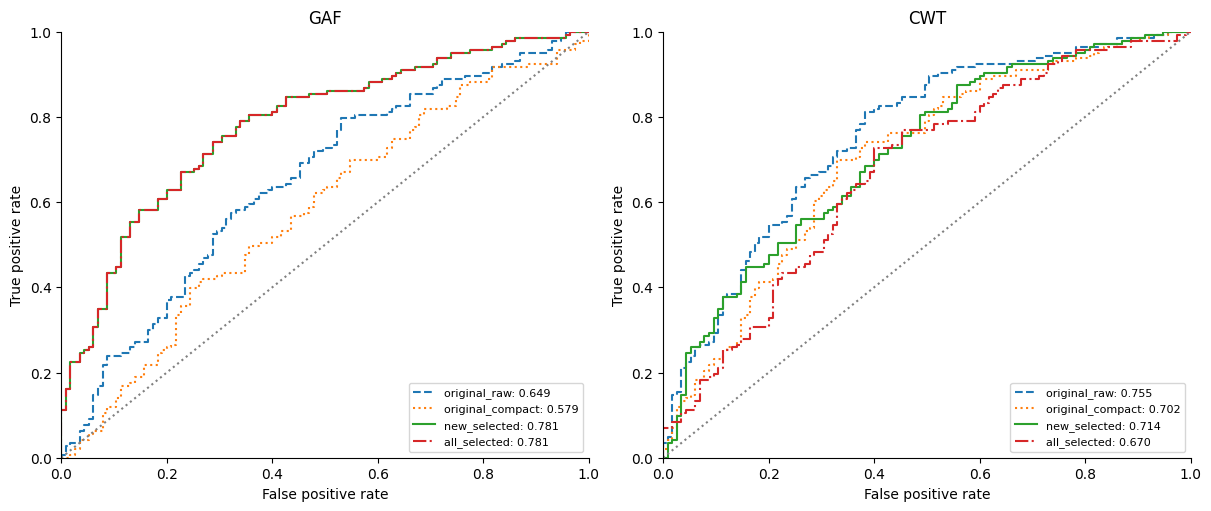

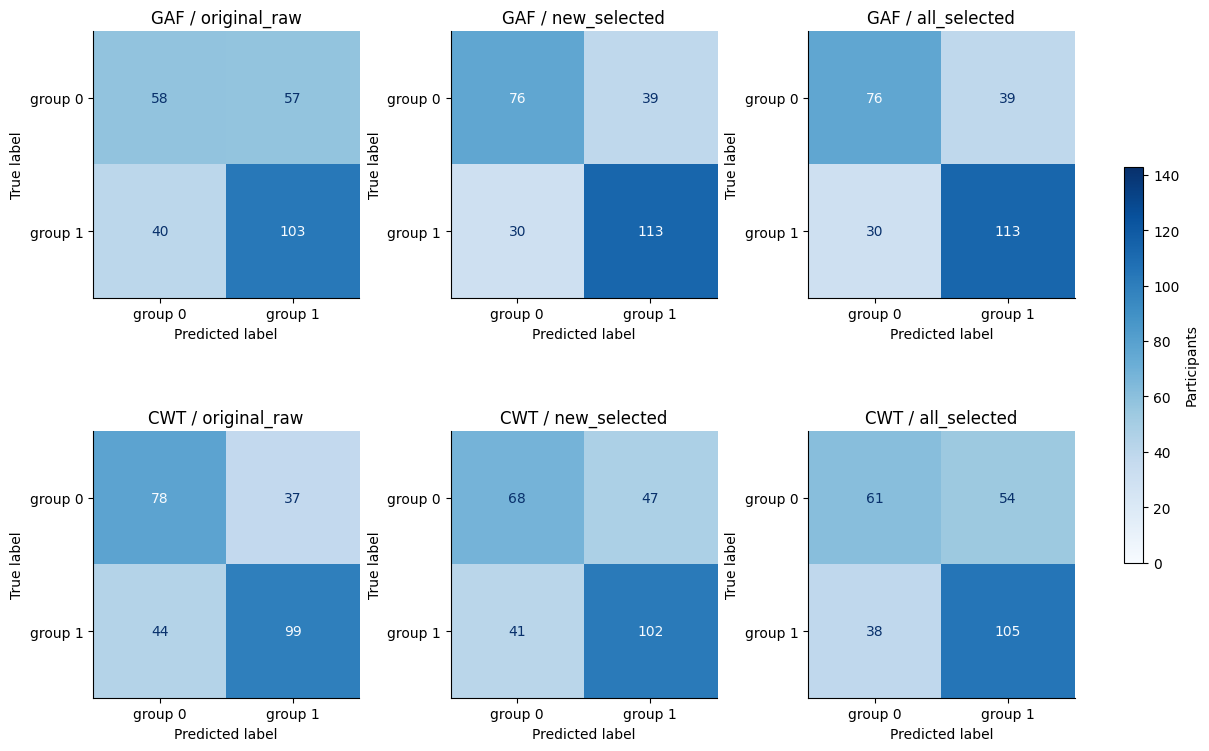

In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for ax,branch in zip(axes,BRANCHES):
    for scenario,style in zip(['original_raw','original_compact','new_selected','all_selected'],['--',':','-','-.']):
        d=oof[(oof.branch==branch)&(oof.scenario==scenario)]
        assert len(d)==258 and d.participant_id.is_unique
        fpr,tpr,_=roc_curve(d.label,d.probability)
        ax.plot(fpr,tpr,ls=style,label=f'{scenario}: {roc_auc_score(d.label,d.probability):.3f}')
    ax.plot([0,1],[0,1],color='gray',ls=':')
    ax.set(title=branch,xlim=(0,1),ylim=(0,1),xlabel='False positive rate',ylabel='True positive rate')
    ax.legend(fontsize=8,loc='lower right')
show(fig,'nested_roc','Pooled OOF ROC; exact original, prior compact and train-selected new/all procedures.', ['nested_oof.csv'])

fig,axes=plt.subplots(2,3,figsize=(12,8),layout='constrained')
for i,branch in enumerate(BRANCHES):
    for j,scenario in enumerate(['original_raw','new_selected','all_selected']):
        d=oof[(oof.branch==branch)&(oof.scenario==scenario)]
        disp=ConfusionMatrixDisplay(confusion_matrix(d.label,d.prediction,labels=[0,1]),display_labels=['group 0','group 1'])
        disp.plot(ax=axes[i,j],cmap='Blues',colorbar=False,values_format='d',im_kw={'vmin':0,'vmax':143})
        axes[i,j].set_title(branch+' / '+scenario)
fig.colorbar(disp.im_,ax=axes,label='Participants',shrink=.5)
show(fig,'nested_confusion','Confusion matrices from stored labels/predictions; shared count scale 0–143.', ['nested_oof.csv'])

## Chi phí và số chiều

Cùng 32 tác vụ, batch 16, warmup và ba lần đo: median throughput, gồm transfer và aggregation,
không gồm tạo ảnh, load model, reducer hay classifier. Đây không phải latency end-to-end.
Peak allocated của PyTorch không phải tổng VRAM của hệ thống.

,branch,mode,n_tasks,repeats,batch_size,median_seconds,min_seconds,max_seconds,estimated_ms_per_participant,peak_gpu_allocated_mb,raw_features,image_generation_seconds
0,GAF,original,32,3,16,0.840013,0.839477,0.842005,367.505819,829.764160,10752,0.093954
1,GAF,group_adapter,32,3,16,0.834675,0.833945,0.835909,365.170356,816.951660,10752,0.093954
2,GAF,channel_mean,32,3,16,5.787979,5.781328,5.820605,2532.240856,881.264160,10752,0.093954
3,GAF,channel_concat,32,3,16,6.058840,6.058386,6.079733,2650.742719,881.264160,75264,0.093954
4,CWT,original,32,3,16,0.188055,0.186861,0.189900,82.274238,427.635742,25088,0.115416
5,CWT,group_adapter,32,3,16,0.186105,0.185399,0.189150,81.421112,414.823242,25088,0.115416
6,CWT,channel_mean,32,3,16,1.238084,1.234989,1.238925,541.661969,479.135742,25088,0.115416
7,CWT,channel_concat,32,3,16,1.234133,1.233638,1.234472,539.933319,479.135742,175616,0.115416


mean        min        max
branch mode                                           
CWT    channel_concat 690.850895 651.846404 746.097422
       channel_mean   110.603940  98.678515 124.295752
       group_adapter  112.877500 101.435617 133.738802
       original              NaN        NaN        NaN
GAF    channel_concat 347.333141 340.237997 352.869631
       channel_mean    50.985868  43.212012  59.265892
       group_adapter   57.391755  49.714778  62.326399
       original              NaN        NaN        NaN

CV job seconds: 24 candidates x (3 inner splits + 1 outer fit); not single-model latency.


bank_fit_seconds  bank_transform_seconds
branch mode           split                                            
CWT    channel_concat inner_0         14.594481                1.006616
                      inner_1         12.082491                0.790155
                      inner_2         10.470135                0.758406
                      outer           19.854363                1.001977
       channel_mean   inner_0          3.603731                0.197430
                      inner_1          2.878337                0.193113
                      inner_2          2.813550                0.167649
                      outer            4.363259                0.213630
       group_adapter  inner_0          3.191038                0.184388
                      inner_1          3.196334                0.190582
                      inner_2          2.343407                0.240577
                      outer            3.693632                0.282176
       original       inner_0               NaN                     NaN
                      inner_1               NaN                     NaN
                      inner_2               NaN                     NaN
                      outer            0.000000                0.000000
GAF    channel_concat inner_0          9.027194                0.487692
                      inner_1          8.885299                0.501331
                      inner_2          8.026078                1.054378
                      outer           13.474865                1.412996
       channel_mean   inner_0          1.724372                0.086265
                      inner_1          1.574771                0.073899
                      inner_2          1.685606                0.082704
                      outer            2.176735                0.091363
       group_adapter  inner_0          1.551438                0.083582
                      inner_1          1.621382                0.090015
                      inner_2          1.662212                0.083217
                      outer            2.520813                0.109490
       original       inner_0               NaN                     NaN
                      inner_1               NaN                     NaN
                      inner_2               NaN                     NaN
                      outer            0.000000                0.000000

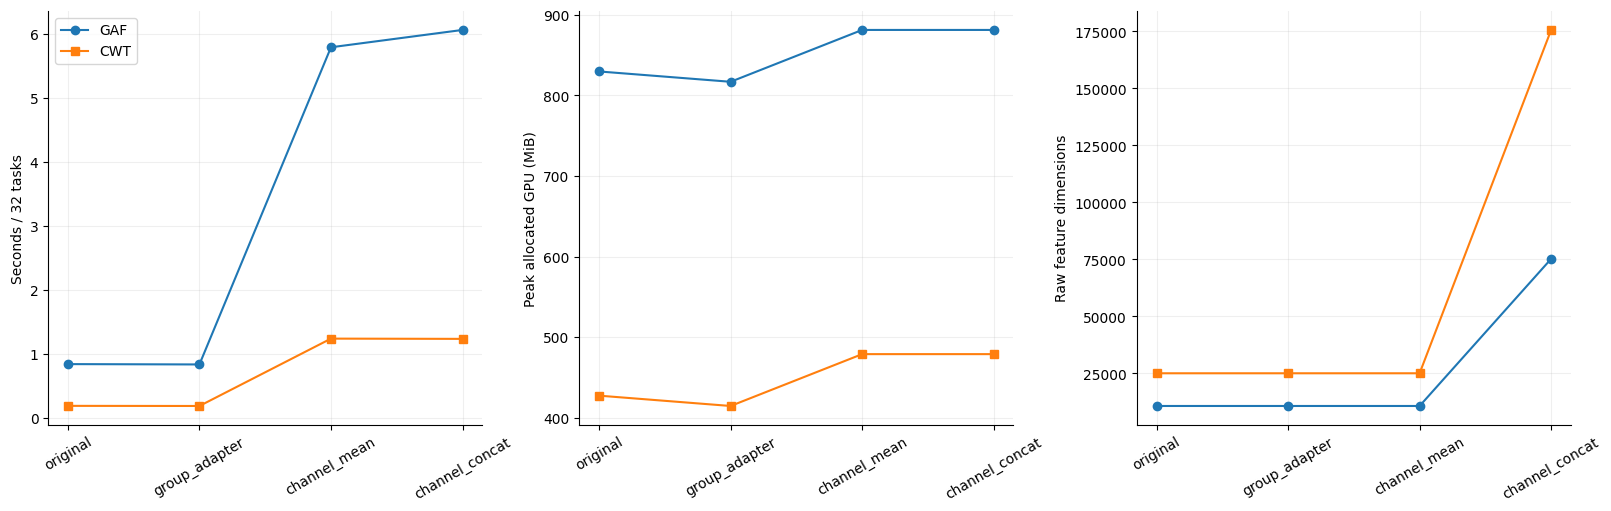

In [11]:
display(costs)
cv_jobs=pd.read_csv(OUT/'cv_job_costs.csv')
display(cv_jobs.groupby(['branch','mode']).seconds.agg(['mean','min','max']))
print('CV job seconds: 24 candidates x (3 inner splits + 1 outer fit); not single-model latency.')
fit_costs=pd.read_csv(OUT/'fit_costs.csv')
display(fit_costs.groupby(['branch','mode','split'])[['bank_fit_seconds','bank_transform_seconds']].mean())
fig,axes=plt.subplots(1,3,figsize=(16,5),layout='constrained')
for branch,marker in [('GAF','o'),('CWT','s')]:
    d=costs[costs.branch==branch].set_index('mode').loc[MODES]
    for ax,column,label in zip(axes,['median_seconds','peak_gpu_allocated_mb','raw_features'],
                               ['Seconds / 32 tasks','Peak allocated GPU (MiB)','Raw feature dimensions']):
        ax.plot(range(4),d[column],marker=marker,label=branch)
        ax.set(xticks=range(4),xticklabels=MODES,ylabel=label)
        ax.tick_params(axis='x',labelrotation=30); ax.grid(alpha=.2)
axes[0].legend()
show(fig,'compute_and_dimensions','Matched warm encoder benchmark: first 32 tasks from three participants, GPU allocation and raw dimensions; excludes classifier/reducer.', ['extraction_costs.csv'],n_participants=3)

## Cấu hình chọn ở từng fold và kiểm tra leakage

Không suy luận “một cấu hình tối ưu đã được xác nhận” từ một quy trình chọn khác nhau giữa fold.
Dữ liệu chi tiết train/test IDs, inner fit IDs và lựa chọn được lưu trong `folds/`, `selections/`.

In [12]:
chosen=selected[selected.scenario.isin(['new_selected','all_selected'])].copy()
chosen['configuration']=chosen['mode']+' / '+chosen.reducer+' / '+chosen.classifier
display(chosen[['branch','scenario','fold','configuration','n_features','outer_accuracy','outer_f1_macro','outer_auc']])
display(pd.read_csv(OUT/'selection_frequency.csv'))
display(pd.read_csv(OUT/'fusion_candidates.csv'))
display(pd.Series({k:v for k,v in validation.items() if k not in ('complete','stage','numerical_artifact_sha256')}))
print('Trạng thái bàn giao cuối cùng: xem results/embedding_ablation/validation.json.')
(FIG/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Báo cáo tiếng Việt:',OUT/'REPORT_VI.md')
print('Không triển khai Fusion trong notebook này.')

,branch,scenario,fold,configuration,n_features,outer_accuracy,outer_f1_macro,outer_auc
48,GAF,new_selected,0,channel_concat / anova_256 / LogisticRegression,256,0.697674,0.686835,0.750000
49,GAF,new_selected,1,group_adapter / anova_256 / SVM,256,0.697674,0.672141,0.800439
50,GAF,new_selected,2,channel_concat / anova_256 / LightGBM,256,0.674419,0.672826,0.692982
51,GAF,new_selected,3,channel_concat / extratrees_256 / SVM,256,0.837209,0.827902,0.866228
52,GAF,new_selected,4,channel_concat / pca_var95 / LogisticRegression,189,0.744186,0.743631,0.861842
53,GAF,new_selected,5,channel_concat / anova_256 / LogisticRegression,256,0.744186,0.739106,0.791667
54,GAF,all_selected,0,channel_concat / anova_256 / LogisticRegression,256,0.697674,0.686835,0.750000
55,GAF,all_selected,1,group_adapter / anova_256 / SVM,256,0.697674,0.672141,0.800439
56,GAF,all_selected,2,channel_concat / anova_256 / LightGBM,256,0.674419,0.672826,0.692982
57,GAF,all_selected,3,channel_concat / extratrees_256 / SVM,256,0.837209,0.827902,0.866228


,branch,scenario,mode,reducer,classifier,outer_folds
0,CWT,all_selected,channel_concat,anova_256,LightGBM,2
1,CWT,all_selected,channel_concat,anova_64,SVM,1
2,CWT,all_selected,original,anova_512,SVM,1
3,CWT,all_selected,original,pca_128,SVM,1
4,CWT,all_selected,original,pca_32,LogisticRegression,1
...,...,...,...,...,...,...
67,GAF,original_compact,original,extratrees_128,LogisticRegression,1
68,GAF,original_compact,original,extratrees_64,SVM,1
69,GAF,original_compact,original,pca_16,LogisticRegression,2
70,GAF,original_raw,original,none,LightGBM,5


,branch,mode,inner_selected_outer_folds,nested_mean_f1_macro,nested_mean_features,raw_features,inference_time_ratio_vs_original,delta_vs_original_raw_f1_macro_pp,delta_vs_original_compact_f1_macro_pp,recommendation
0,GAF,group_adapter,1,0.636474,195.000000,10752,0.993645,2.696063,8.368425,candidate_for_future_fusion_ablation
1,GAF,channel_mean,0,0.711806,1863.500000,10752,6.890342,10.229312,15.901673,candidate_for_future_fusion_ablation
2,GAF,channel_concat,5,0.726995,233.833333,75264,7.212791,11.748237,17.420598,candidate_for_future_fusion_ablation
3,CWT,group_adapter,0,0.663752,12663.166667,25088,0.989631,-1.727983,1.585756,retain_as_control_only
4,CWT,channel_mean,0,0.603782,8486.666667,25088,6.583616,-7.725004,-4.411265,retain_as_control_only
5,CWT,channel_concat,6,0.649781,208.000000,175616,6.562605,-3.125078,0.188661,retain_as_control_only


numerical_validation_passed                True
fixed_results                               192
outer_records                                48
new_outer_records                            36
new_inner_fit_partitions                    108
original_artifacts_unchanged                707
original_fixed_and_nested_oof_exact        True
participant_identity_and_folds_verified    True
all_metrics_recomputed_from_oof            True
train_only_transform_audits_passed         True
encoder_and_adapter_frozen                 True
seed                                         42
n_subjects                                  258
dtype: object

Trạng thái bàn giao cuối cùng: xem results/embedding_ablation/validation.json.
Báo cáo tiếng Việt: E:\DiaGraMo-project\results\embedding_ablation\REPORT_VI.md
Không triển khai Fusion trong notebook này.
